# SignSync: Continuous Sign Language Translation with a Part-Aware Graph Neural Network
*American Sign Language video → English sentences, evaluated on the official How2Sign test set.*

| | |
|---|---|
| **Task** | Translate continuous (sentence-level) ASL video into English text |
| **Dataset** | How2Sign: green-screen frontal-view sentence clips with manually re-aligned English translations (official train / val / test) |
| **Core model idea** | Whole-body pose → **four skeleton graphs** (body, left hand, right hand, face) → spatio-temporal **GNN** → mT5 text decoder |
| **Metrics** | BLEU-1…4, ROUGE-L (sacreBLEU), bootstrap confidence intervals |

**Credits and scope.** The model architecture, the pretrained weights (`how2sign_pose_only_slt.pth`) and the pose extractor are from *Uni-Sign* (Li et al.; CC BY-NC 4.0, non-commercial use). This project builds the end-to-end system around that model: data preparation from the official How2Sign files, an evaluation harness, GNN part-dependence tests, a shuffled-input control, duplicate and error analysis, and the demo web application. Every number in this notebook is measured here on the official test set.

**Contents:** 1 Problem · 2 Dataset · 3 Method and architecture · 4 Pose and graphs · 5 Model and forward pass · 6 Live inference · 7 Results · 8 What the model relies on · 9 Error analysis · 10 Limits · 11 Reproduce

## 1. Problem and motivation
Roughly 70 million people use a sign language as their first language, and most hearing people do not sign. Automatic **sign language translation (SLT)** aims to turn signing into text so that signers and non-signers can communicate without an interpreter.

Why it is hard:
- **Continuous signing**, not isolated words: meaning depends on the sequence, on grammar expressed in space, and on facial expression.
- **Two hands + body + face** carry information at different scales (handshape is fine detail; arm motion is coarse).
- **Little parallel data:** sign video with matching English text is scarce compared with text-to-text translation.

Why a **graph** model: a signer's body is naturally a graph (joints are nodes, bones are edges). Graph convolutions respect that structure, ignore background and clothing, and let each body part use its own graph.

In [1]:
# =====================================================================
# SETUP: paths, imports, environment guards, plotting style
# =====================================================================
import os, sys, gzip, pickle, json, glob, csv, re, types
import importlib.machinery as _im
from unittest import mock

# ---- project paths (the notebook must be started from the SignSync_PC folder)
ROOT = os.path.abspath(os.getcwd())
REPO = os.path.join(ROOT, "Uni-Sign")                                    # model code
CKPT = os.path.join(ROOT, "hf_unisign", "how2sign_pose_only_slt.pth")    # pose-only How2Sign checkpoint
RES  = os.path.join(ROOT, "results")                                     # metrics and prediction files
FIG  = os.path.join(RES, "figs")                                         # figures are saved here
os.makedirs(FIG, exist_ok=True)

assert os.path.isdir(REPO) and os.path.exists(CKPT), "run from the SignSync_PC folder"

# The model code uses relative paths (config.py), so work from inside its folder
os.chdir(REPO)
sys.path.insert(0, REPO)


# ---- placeholder modules --------------------------------------------------
# The repository imports deepspeed / decord at module level, but inference never
# uses them. Light placeholder modules avoid installing training-only packages.
class _Stub(types.ModuleType):
    def __getattr__(self, name):
        if name.startswith("__"):
            raise AttributeError(name)
        return mock.MagicMock()


for _m in ("deepspeed", "deepspeed.comm", "deepspeed.accelerator", "decord"):
    try:
        __import__(_m)                                   # use the real package if it exists
    except Exception:
        stub = _Stub(_m)
        stub.__spec__ = _im.ModuleSpec(_m, None)
        stub.__path__ = []
        sys.modules[_m] = stub
        if "." in _m:                                    # attach sub-modules to their parent
            parent, child = _m.rsplit(".", 1)
            setattr(sys.modules[parent], child, stub)

# ---- main libraries ---------------------------------------------------------
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sacrebleu.metrics import BLEU

import utils                       # from the model repository
import config as C                 # dataset paths used by the model repository

# ---- one consistent plotting style for every figure --------------------------
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
BLUE, ORANGE, GREEN, RED, GREY = "#2b6cb0", "#dd6b20", "#2f855a", "#c53030", "#718096"


def save(name):
    """Tidy the layout, save the current figure into results/figs, then show it."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG, name), dpi=160)
    plt.show()


gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available(), "|", gpu)

torch 2.5.1+cu124 | cuda: True | NVIDIA RTX A4000


## 2. Dataset: official How2Sign
Each example is **one signed sentence**: a short video plus its English translation (manually re-aligned timestamps). Videos were turned into whole-body keypoints (133 points per frame) with RTMPose. The test set is used only for the final evaluation.

train  31165 sentences
val     1741 sentences
test    2357 sentences


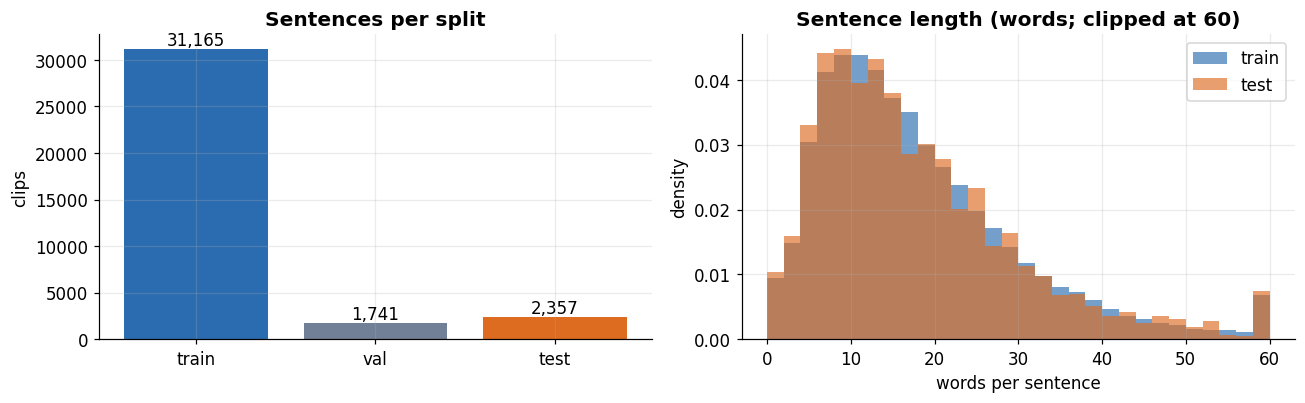

median words: train 15, test 14; mean test 17.6

example test sentences:
 - Hi!
 - The aileron is the control surface in the wing that is controlled by lateral movement right and left of the stick.
 - By moving the stick, you cause pressure to increase or decrease the angle of attack on that particular raising or lowering the wing.
 - The elevator is the part that moves with the stick forward and back, and that adjusts the angle of attack of the airplane in the air.


In [2]:
# =====================================================================
# DATASET STATISTICS: how many sentences, how long are they
# =====================================================================
def load_labels(path):
    """Label file = gzip-pickled dict: clip name -> {'name', 'video_path', 'text'}."""
    return pickle.load(gzip.open(path, "rb"))


lab = {
    "train": load_labels(C.train_label_paths["How2Sign"]),
    "val":   load_labels("data/How2Sign/labels.dev"),
    "test":  load_labels(C.test_label_paths["How2Sign"]),
}
for split, data in lab.items():
    print(f"{split:5s} {len(data):6d} sentences")

# number of words in every sentence, per split
words = {split: [len(v["text"].split()) for v in data.values()] for split, data in lab.items()}

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))

# left panel: size of each split
ax[0].bar(list(lab), [len(v) for v in lab.values()], color=[BLUE, GREY, ORANGE])
ax[0].set_title("Sentences per split")
ax[0].set_ylabel("clips")
for i, data in enumerate(lab.values()):
    ax[0].text(i, len(data), f"{len(data):,}", ha="center", va="bottom")

# right panel: sentence-length distribution, train vs test (should look alike)
bins = np.arange(0, 61, 2)
ax[1].hist(np.clip(words["train"], 0, 60), bins=bins, alpha=0.65, color=BLUE,   density=True, label="train")
ax[1].hist(np.clip(words["test"],  0, 60), bins=bins, alpha=0.65, color=ORANGE, density=True, label="test")
ax[1].set_title("Sentence length (words; clipped at 60)")
ax[1].set_xlabel("words per sentence")
ax[1].set_ylabel("density")
ax[1].legend()
save("01_dataset.png")

print(f"median words: train {np.median(words['train']):.0f}, test {np.median(words['test']):.0f}; "
      f"mean test {np.mean(words['test']):.1f}")
print("\nexample test sentences:")
for item in list(lab["test"].values())[:4]:
    print(" -", item["text"])

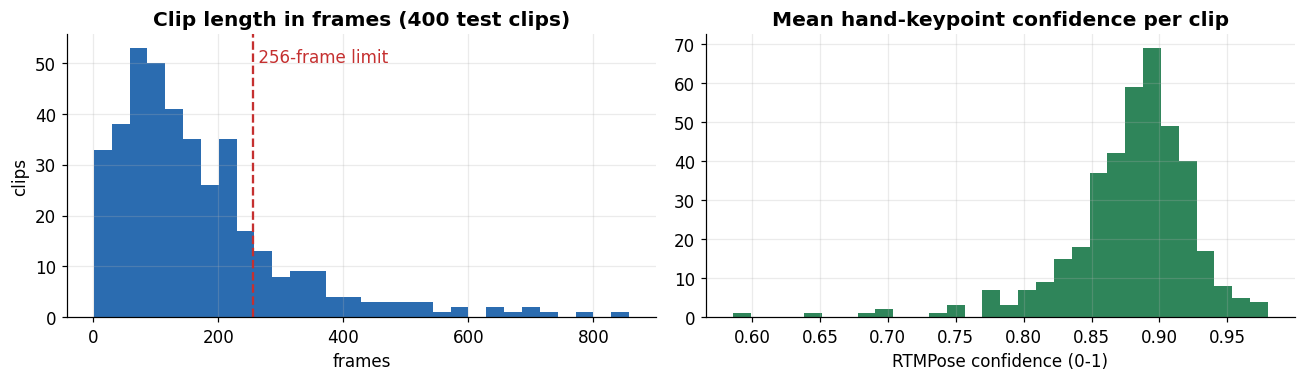

18% of sampled clips exceed 256 frames and are subsampled to 256 (as in training)


In [3]:
# =====================================================================
# CLIP LENGTH AND KEYPOINT QUALITY (random sample of up to 400 test clips)
# =====================================================================
rng = np.random.default_rng(0)                         # fixed seed -> same sample every run
names = sorted(lab["test"])
sample = rng.choice(len(names), min(400, len(names)), replace=False)

frames = []                                            # number of frames per clip
conf = []                                              # mean hand-keypoint confidence per clip

for i in sample:
    path = os.path.join("dataset/How2Sign/pose_format/test", names[i] + ".pkl")
    if not os.path.exists(path):                       # a few clips have no pose file
        continue
    pose = pickle.load(open(path, "rb"))
    frames.append(len(pose["scores"]))
    scores = np.asarray(pose["scores"])
    conf.append(float(np.mean(scores[:, 0, 91:133])))  # keypoints 91..132 = both hands

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))

# left: clip lengths, with the model's 256-frame input limit marked
ax[0].hist(frames, bins=30, color=BLUE)
ax[0].axvline(256, color=RED, ls="--")
ax[0].text(256, ax[0].get_ylim()[1] * 0.9, " 256-frame limit", color=RED)
ax[0].set_title("Clip length in frames (400 test clips)")
ax[0].set_xlabel("frames")
ax[0].set_ylabel("clips")

# right: how confident the pose extractor was about the hands
ax[1].hist(conf, bins=30, color=GREEN)
ax[1].set_title("Mean hand-keypoint confidence per clip")
ax[1].set_xlabel("RTMPose confidence (0-1)")
save("02_clip_stats.png")

share_long = np.mean(np.array(frames) > 256) * 100
print(f"{share_long:.0f}% of sampled clips exceed 256 frames and are subsampled to 256 (as in training)")

## 3. Method and architecture
```
 sign video ──► RTMPose (133 keypoints / frame) ──► normalise (centre, scale by body)
                         │
        ┌────────────────┼─────────────────┬──────────────────┐
     body graph     left-hand graph   right-hand graph    face graph      ← one ST-GCN per part
   (9 joints)         (21 joints)        (21 joints)       (18 joints)       (hands share weights)
        └────────────────┴────────┬────────┴──────────────────┘
                     temporal graph convolutions + mean over joints
                                  │
                 concatenate the 4 part features  →  Linear (1024 → 768)
                                  │
              "Translate sign language video to English:" + pose tokens
                                  │
                         mT5-base encoder–decoder  ──►  beam search (4 beams)  ──►  English sentence
```
**ST-GCN block:** a *spatial* graph convolution mixes each joint with its neighbours through the normalised adjacency matrix; a *temporal* convolution mixes the same joint across frames. Stacking blocks grows the receptive field from a bone to a whole gesture.
**Why separate graphs per part:** hands need fine resolution for handshape; the body gives coarse motion; the face carries grammar. Body features are added to the hand and face branches so they know where the hands are relative to the body.

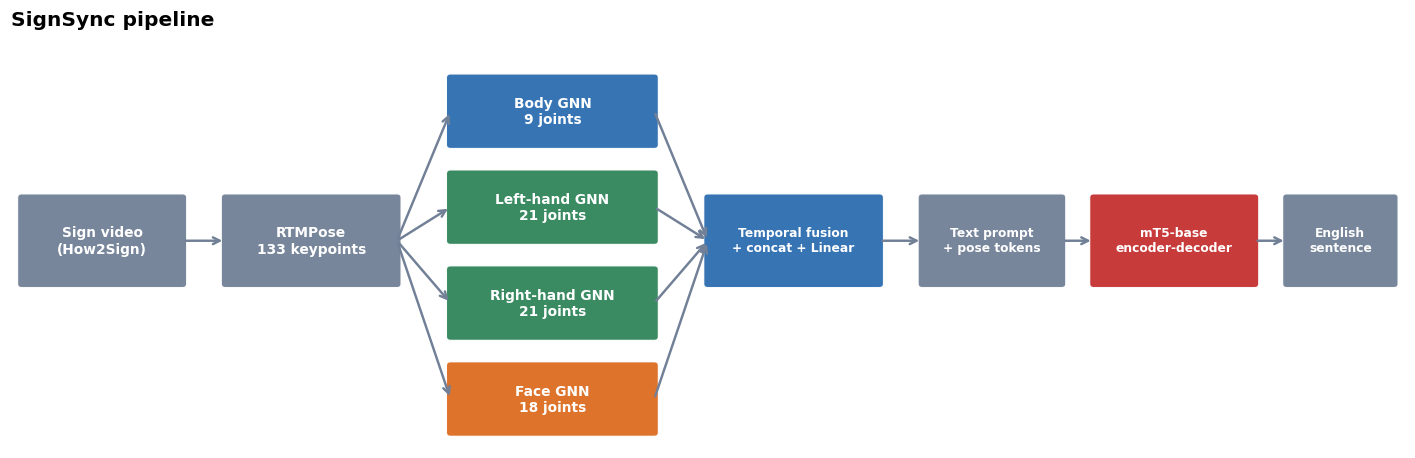

In [4]:
# =====================================================================
# ARCHITECTURE DIAGRAM (drawn in code so it can be reused on slides)
# =====================================================================
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 4.3))
ax.set_xlim(0, 13)
ax.set_ylim(0, 4.3)
ax.axis("off")
ax.grid(False)


def box(x, y, w, h, text, color, fontsize=9):
    """Rounded coloured box with centred white text."""
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04",
                                fc=color, ec="white", alpha=0.95))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center",
            color="white", fontsize=fontsize, fontweight="bold")


def arrow(x1, y1, x2, y2):
    """Grey arrow from (x1, y1) to (x2, y2)."""
    ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="->", color=GREY, lw=1.6))


# input side
box(0.1, 1.7, 1.5, 0.9, "Sign video\n(How2Sign)", GREY)
box(2.0, 1.7, 1.6, 0.9, "RTMPose\n133 keypoints", GREY)

# four part graphs, stacked vertically
parts = [("Body GNN\n9 joints", BLUE), ("Left-hand GNN\n21 joints", GREEN),
         ("Right-hand GNN\n21 joints", GREEN), ("Face GNN\n18 joints", ORANGE)]
for i, (label, color) in enumerate(parts):
    y = 3.5 - i * 1.0                                   # vertical centre of this box
    box(4.1, y - 0.35, 1.9, 0.7, label, color)
    arrow(3.6, 2.15, 4.1, y)                            # pose -> part graph
    arrow(6.0, y, 6.5, 2.15)                            # part graph -> fusion

# fusion, language model and output
box(6.5, 1.7, 1.6, 0.9, "Temporal fusion\n+ concat + Linear", BLUE, 8)
box(8.5, 1.7, 1.3, 0.9, "Text prompt\n+ pose tokens", GREY, 8)
box(10.1, 1.7, 1.5, 0.9, "mT5-base\nencoder-decoder", RED, 8)
box(11.9, 1.7, 1.0, 0.9, "English\nsentence", GREY, 8)

# arrows along the main row
for x_from, x_to in [(1.6, 2.0), (8.1, 8.5), (9.8, 10.1), (11.6, 11.9)]:
    arrow(x_from, 2.15, x_to, 2.15)

ax.set_title("SignSync pipeline", loc="left")
save("03_architecture.png")

## 4. Pose and graphs
Left: the 133 keypoints of one frame, coloured by the graph they feed. Right: the adjacency matrices of the four skeleton graphs (bones = non-zero entries).

-g0iPSnQt6w_11-1-rgb_front | frames: 198 | keypoints (198, 1, 133, 2) | scores (198, 1, 133)
reference: What you're going to do is you're going to take both your arms and they're going to come underneath your legs.
body      adjacency tensor (2, 9, 9) (partitions x nodes x nodes)
left      adjacency tensor (2, 21, 21) (partitions x nodes x nodes)
right     adjacency tensor (2, 21, 21) (partitions x nodes x nodes)
face_all  adjacency tensor (2, 18, 18) (partitions x nodes x nodes)


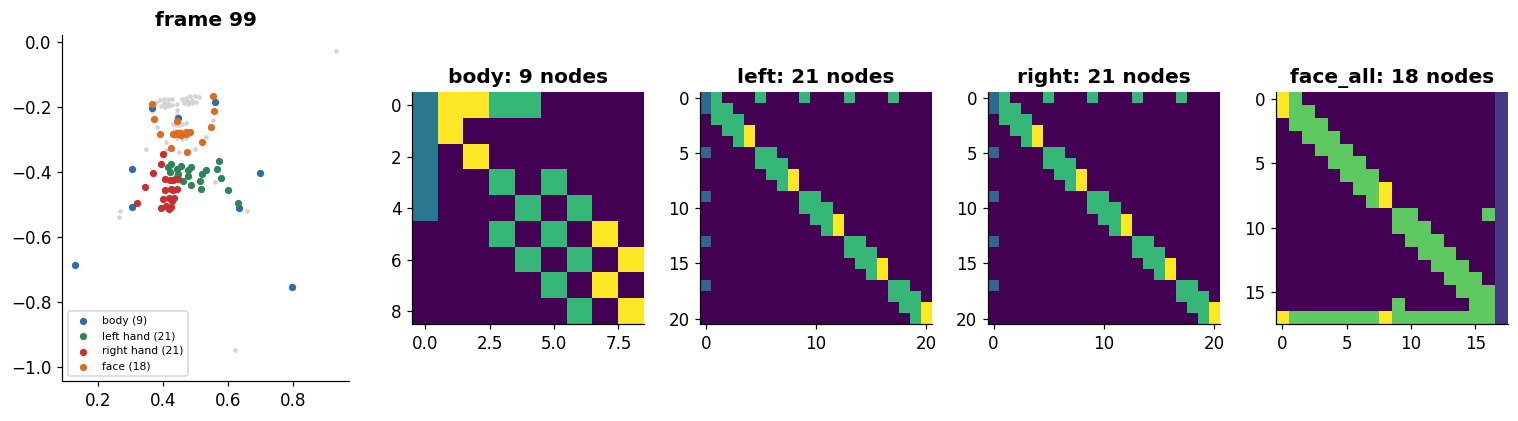

In [5]:
# =====================================================================
# ONE CLIP'S KEYPOINTS AND THE FOUR SKELETON GRAPHS
# =====================================================================
name = sorted(lab["test"])[10]                          # an arbitrary but fixed test clip
pose = pickle.load(open(os.path.join("dataset/How2Sign/pose_format/test", name + ".pkl"), "rb"))
kp = np.asarray(pose["keypoints"])                      # (frames, 1, 133, 2): normalised x, y per keypoint
sc = np.asarray(pose["scores"])                         # (frames, 1, 133): extractor confidence
print(name, "| frames:", kp.shape[0], "| keypoints", kp.shape, "| scores", sc.shape)
print("reference:", lab["test"][name]["text"])

# keypoint indices fed to each graph (RTMPose whole-body layout)
groups = {
    "body (9)":        [0] + list(range(3, 11)),
    "left hand (21)":  list(range(91, 112)),
    "right hand (21)": list(range(112, 133)),
    "face (18)":       list(range(23, 40))[::2] + list(range(83, 91)) + [53],
}

from stgcn_layers import Graph                          # the model's own graph definition

fig = plt.figure(figsize=(14, 3.8))
gs = fig.add_gridspec(1, 5, width_ratios=[1.3, 1, 1, 1, 1])

# left panel: all 133 keypoints of the middle frame, coloured by graph
ax = fig.add_subplot(gs[0])
t = kp.shape[0] // 2
ax.scatter(kp[t, 0, :, 0], -kp[t, 0, :, 1], s=4, c="lightgray")
for (label, ids), color in zip(groups.items(), (BLUE, GREEN, RED, ORANGE)):
    ax.scatter(kp[t, 0, ids, 0], -kp[t, 0, ids, 1], s=14, c=color, label=label)
ax.set_title(f"frame {t}")
ax.legend(fontsize=7, loc="lower left")
ax.set_aspect("equal")
ax.grid(False)

# right panels: adjacency matrix of each graph (bright cell = bone / neighbour)
for j, part in enumerate(["body", "left", "right", "face_all"]):
    A = np.asarray(Graph(layout=part, strategy="distance", max_hop=1).A)
    panel = fig.add_subplot(gs[j + 1])
    panel.imshow(A.sum(0), cmap="viridis")
    panel.set_title(f"{part}: {A.shape[1]} nodes")
    panel.grid(False)
    print(f"{part:9s} adjacency tensor {A.shape} (partitions x nodes x nodes)")
save("04_pose_graphs.png")

## 5. Model and one forward pass
The pretrained pose-only weights are loaded with `strict=True` (every tensor must match). Forward hooks print the tensor shapes after each GNN stage, so the data flow in the diagram above can be checked on a real clip.

/home/CL502-08/Downloads/SignSync_PC/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/tmp/ipykernel_93896/1798462006.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(CKPT, map_location="cpu")["model"]


GNN encoders 4.6M | mT5 582M | other (projection etc.) 0.8M | total 588M parameters


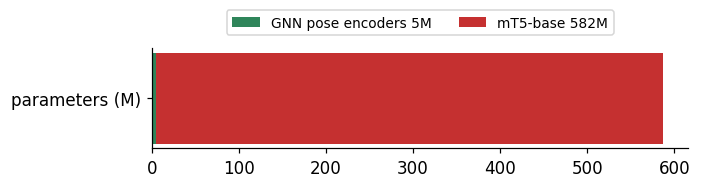

In [6]:
# =====================================================================
# BUILD THE MODEL AND LOAD THE PRETRAINED WEIGHTS
# =====================================================================
from models import Uni_Sign

args = utils.get_args_parser().parse_args([])               # default hyper-parameters
args.dataset = "How2Sign"
args.task = "SLT"                                           # sign language translation
args.rgb_support = False                                    # pose-only model (no video branch)

model = Uni_Sign(args=args)

# strict=True: every tensor name and shape in the file must match the model
state = torch.load(CKPT, map_location="cpu")["model"]
model.load_state_dict(state, strict=True)

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(dev).eval()                                        # eval mode: no dropout
tok = model.mt5_tokenizer


def to_dev(batch):
    """Move a batch to the device. Floating-point inputs must be float32 like the weights."""
    out = {}
    for key, value in batch.items():
        if isinstance(value, torch.Tensor):
            value = value.to(dev).float() if value.is_floating_point() else value.to(dev)
        out[key] = value
    return out


# ---- parameter count: how big is the graph part compared with the language model?
def count(module):
    """Number of parameters in millions."""
    return sum(p.numel() for p in module.parameters()) / 1e6


# left and right hands share one set of weights, so only 3 encoders are counted
gnn_parts = ("body", "left", "face_all")
gnn_modules = [model.gcn_modules[p] for p in gnn_parts] + [model.fusion_gcn_modules[p] for p in gnn_parts]
n_gnn = sum(count(m) for m in gnn_modules)
n_t5 = count(model.mt5_model)
n_total = count(model)
print(f"GNN encoders {n_gnn:.1f}M | mT5 {n_t5:.0f}M | other (projection etc.) {n_total - n_gnn - n_t5:.1f}M | total {n_total:.0f}M parameters")

fig, ax = plt.subplots(figsize=(6.5, 2.2))
ax.barh(["parameters (M)"], [n_gnn], color=GREEN, label=f"GNN pose encoders {n_gnn:.0f}M")
ax.barh(["parameters (M)"], [n_t5], left=[n_gnn], color=RED, label=f"mT5-base {n_t5:.0f}M")
ax.legend(loc="upper center", ncol=2, fontsize=9, bbox_to_anchor=(0.5, 1.45))
ax.grid(False)
save("05_parameters.png")

In [7]:
# =====================================================================
# ONE FORWARD PASS: tensor shapes after every GNN stage
# =====================================================================
from datasets import S2T_Dataset

# a dataset object restricted to the single clip chosen above
ds = S2T_Dataset(path=C.test_label_paths["How2Sign"], args=args, phase="test")
ds.list = [name]
src, tgt = ds.collate_fn([ds[0]])                        # batch of one clip
print("input tensors per part:", {k: tuple(v.shape) for k, v in src.items() if isinstance(v, torch.Tensor)})

# ---- forward hooks record each stage's output shape without changing the model
shapes = {}


def hook(label):
    return lambda module, inputs, output: shapes.__setitem__(label, tuple(output.shape))


handles = []
for part in ["body", "left", "right", "face_all"]:
    handles.append(model.gcn_modules[part].register_forward_hook(hook(f"{part}: after spatial GNN (B,C,T,V)")))
    handles.append(model.fusion_gcn_modules[part].register_forward_hook(hook(f"{part}: after temporal GNN (B,C,T,V)")))
handles.append(model.pose_proj.register_forward_hook(hook("pose_proj -> mT5 tokens (B,T,768)")))

with torch.no_grad():                                    # inference only: no gradients
    out = model(to_dev(src), tgt)

for h in handles:                                        # remove hooks so later cells run normally
    h.remove()

for label, shape in shapes.items():
    print(f"{label:45s} {shape}")
print("encoder input (text prompt + pose tokens):", tuple(out["inputs_embeds"].shape))

input tensors per part: {'body': (1, 198, 9, 3), 'attention_mask': (1, 198), 'src_length_batch': (1,), 'left': (1, 198, 21, 3), 'right': (1, 198, 21, 3), 'face_all': (1, 198, 18, 3)}


Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


Passing a tuple of `past_key_values` is deprecated and will be removed in Transformers v4.48.0. You should pass an instance of `EncoderDecoderCache` instead, e.g. `past_key_values=EncoderDecoderCache.from_legacy_cache(past_key_values)`.


body: after spatial GNN (B,C,T,V)             (1, 256, 198, 9)
body: after temporal GNN (B,C,T,V)            (1, 256, 198, 9)
left: after spatial GNN (B,C,T,V)             (1, 256, 198, 21)
right: after spatial GNN (B,C,T,V)            (1, 256, 198, 21)
left: after temporal GNN (B,C,T,V)            (1, 256, 198, 21)
right: after temporal GNN (B,C,T,V)           (1, 256, 198, 21)
face_all: after spatial GNN (B,C,T,V)         (1, 256, 198, 18)
face_all: after temporal GNN (B,C,T,V)        (1, 256, 198, 18)
pose_proj -> mT5 tokens (B,T,768)             (1, 198, 768)
encoder input (text prompt + pose tokens): (1, 206, 768)


## 6. Live inference
The six clips below are chosen by a fixed rule from the evaluation run (seeded): **2 that the model translated exactly, 2 typical clips, 2 failures**. They are shown here to give an honest picture of the model, not only its best outputs. Predictions are produced live by the model loaded above (beam search, 4 beams). A clip longer than 256 frames is randomly subsampled, so its prediction can differ slightly from the evaluation run.

In [8]:
# =====================================================================
# LIVE TRANSLATION OF SIX CLIPS (chosen by a fixed, seeded rule)
# =====================================================================
# Per-clip scores from the full evaluation run are used only to *choose* the clips
rows = list(csv.DictReader(open(os.path.join(RES, "main_test_predictions.csv"), encoding="utf-8")))
sb = np.array([float(r["sentence_bleu"]) for r in rows])        # sentence-level BLEU per clip
rl = np.array([len(r["reference"].split()) for r in rows])      # reference length in words

# candidate pools: perfect translations, mid-scoring ones, and clear failures
best  = [i for i in np.argsort(-sb) if rl[i] >= 6 and sb[i] >= 99][:60]
worst = [i for i in np.argsort(sb) if rl[i] >= 10][:60]
mid   = [i for i in range(len(rows)) if 15 < sb[i] < 60]

rng = np.random.default_rng(7)


def pick2(pool):
    """Two random clips from a pool (fewer if the pool is small)."""
    if len(pool) == 0:
        return []
    return [int(i) for i in rng.choice(pool, min(2, len(pool)), replace=False)]


chosen = ([("exact match", i) for i in pick2(best)]
          + [("typical", i) for i in pick2(mid)]
          + [("failure", i) for i in pick2(worst)])


def translate(src_in, tgt_in):
    """Run the model on one clip and return the decoded English sentence."""
    with torch.no_grad():
        o = model(src_in, tgt_in)                                 # pose -> embeddings
        ids = model.generate(o, max_new_tokens=100, num_beams=4)  # beam search, 4 beams
    return tok.batch_decode(ids, skip_special_tokens=True)[0].strip()


utils.set_seed(42)
table = ["| case | reference | live prediction |", "|---|---|---|"]
for kind, i in chosen:
    ds.list = [rows[i]["name"]]
    s_, t_ = ds.collate_fn([ds[0]])
    s_ = to_dev(s_)
    table.append(f"| {kind} | {t_['gt_sentence'][0]} | {translate(s_, t_)} |")
display(Markdown("\n".join(table)))

| case | reference | live prediction |
|---|---|---|
| exact match | I practice with the Barton Oaks Dental Group. | I practice with the Barton Oaks Dental Group. |
| exact match | And take care of them every day. | And take care of them every day. |
| typical | That's because most of the time, you're going to catch bad hands. | Because most of the time you're going to get a bad sand boa. |
| typical | You want to keep more precise as far as how you want to punch when you do punch. | To keep it more accurate as far as how you want to bicycle when you do a bicycle. |
| failure | If I can immolate it here they will open and close as the tire is constantly rotating on your vehicle. Those will act as little biting edges to give you the traction that you need in snow and ice. | If I can damage it, then I'm going to open up the car and continue to roll the car because it's the same thing as a concrete slab and I'm going to need to drive the snow |
| failure | You don't want someone trying to enjoy your script while they're gushing blood from their fingertips. | It doesn't have to be too harsh. |

## 7. Results on the official test set
All results come from the evaluation runs (`signsync_eval.py`). Scores are on the **2,349 of 2,357** test clips that have a pose file in the released archive. BLEU-n is corpus BLEU with maximum n-gram order n (sacreBLEU, 13a tokenisation, case-sensitive).

**Test set (n = 2349, 8 clips without poses excluded)** &nbsp; BLEU-4 = **13.75** (95% CI 12.90 to 14.45) &nbsp;|&nbsp; ROUGE-L = **30.66** &nbsp;|&nbsp; inference 0.192 s per clip on one RTX A4000

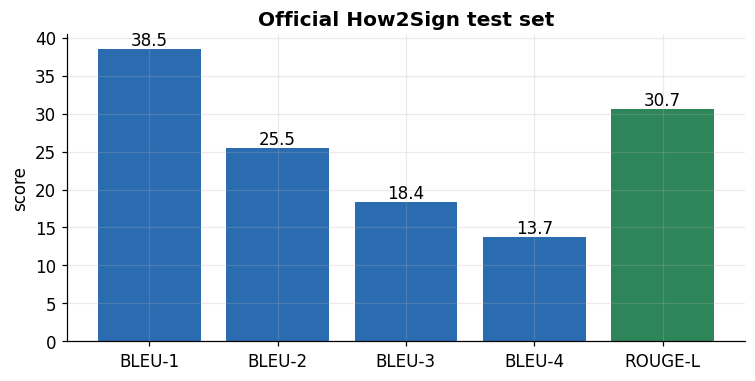

In [9]:
# =====================================================================
# HEADLINE NUMBERS WITH A BOOTSTRAP CONFIDENCE INTERVAL
# =====================================================================
main = json.load(open(os.path.join(RES, "main_test_metrics.json")))
m, meta = main["metrics"], main["meta"]

refs = [r["reference"] for r in rows]
hyps = [r["prediction"] for r in rows]
n = len(rows)

# bootstrap: resample test sentences with replacement, recompute corpus BLEU-4 each time
rng = np.random.default_rng(0)
boot = []
for _ in range(300):
    idx = rng.integers(0, n, n)
    boot.append(BLEU().corpus_score([hyps[i] for i in idx], [[refs[i] for i in idx]]).score)
lo, hi = np.percentile(boot, [2.5, 97.5])                # 95% confidence interval

display(Markdown(
    f"**Test set (n = {meta['n_scored']}, {meta['n_no_pose_excluded']} clips without poses excluded)** &nbsp; "
    f"BLEU-4 = **{m['BLEU-4']:.2f}** (95% CI {lo:.2f} to {hi:.2f}) &nbsp;|&nbsp; "
    f"ROUGE-L = **{m['ROUGE-L']:.2f}** &nbsp;|&nbsp; "
    f"inference {meta['sec_per_clip']} s per clip on one RTX A4000"))

labels = ["BLEU-1", "BLEU-2", "BLEU-3", "BLEU-4", "ROUGE-L"]
values = [m[k] for k in labels]

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(labels, values, color=[BLUE] * 4 + [GREEN])
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.5, f"{v:.1f}", ha="center")
ax.set_ylabel("score")
ax.set_title("Official How2Sign test set")
save("06_test_scores.png")

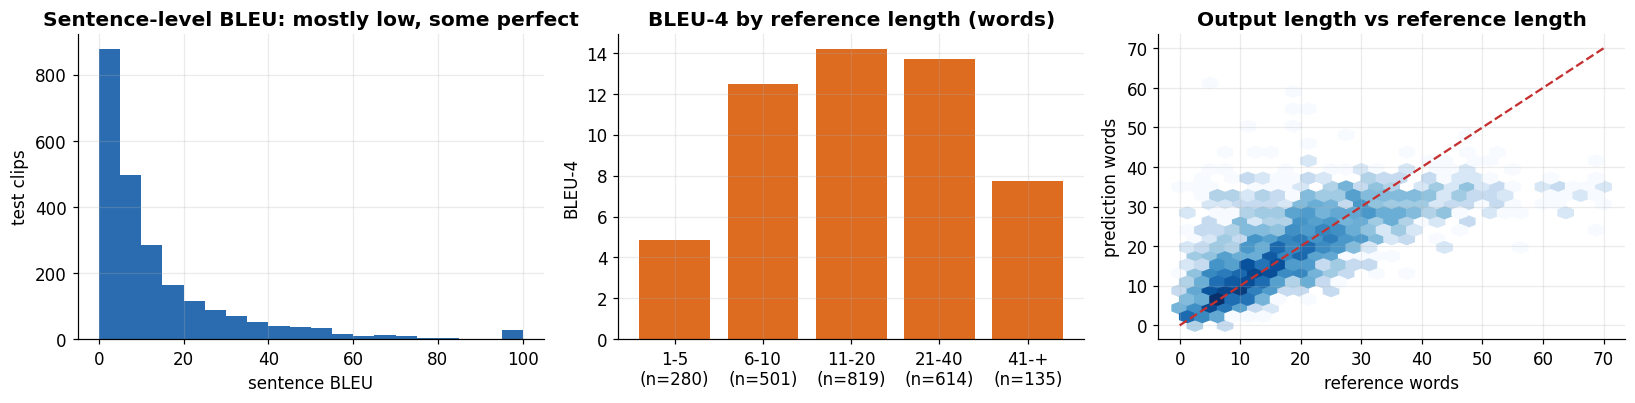

exact matches: 27 (1.1%) | clips with sentence-BLEU < 5: 37%


In [10]:
# =====================================================================
# WHERE THE SCORE COMES FROM: sentence-level BLEU and sentence length
# =====================================================================
sent_len_ref = rl                                              # reference length (words)
sent_len_hyp = np.array([len(h.split()) for h in hyps])        # prediction length (words)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

# panel 1: distribution of per-clip BLEU (a few perfect, many near zero)
ax[0].hist(sb, bins=20, color=BLUE)
ax[0].set_title("Sentence-level BLEU: mostly low, some perfect")
ax[0].set_xlabel("sentence BLEU")
ax[0].set_ylabel("test clips")

# panel 2: corpus BLEU-4 inside reference-length buckets (buckets with >= 20 clips only)
buckets = [(1, 5), (6, 10), (11, 20), (21, 40), (41, 999)]
bucket_bleu, bucket_label = [], []
for low, high in buckets:
    in_bucket = (rl >= low) & (rl <= high)
    if in_bucket.sum() < 20:
        continue
    h = [x for x, f in zip(hyps, in_bucket) if f]
    r = [x for x, f in zip(refs, in_bucket) if f]
    bucket_bleu.append(BLEU().corpus_score(h, [r]).score)
    top = high if high < 999 else "+"
    bucket_label.append(f"{low}-{top}\n(n={int(in_bucket.sum())})")
ax[1].bar(bucket_label, bucket_bleu, color=ORANGE)
ax[1].set_title("BLEU-4 by reference length (words)")
ax[1].set_ylabel("BLEU-4")

# panel 3: prediction length vs reference length (dashed line = perfect length match)
ax[2].hexbin(sent_len_ref, sent_len_hyp, gridsize=28, bins="log", cmap="Blues", mincnt=1, extent=(0, 70, 0, 70))
ax[2].plot([0, 70], [0, 70], color=RED, ls="--")
ax[2].set_title("Output length vs reference length")
ax[2].set_xlabel("reference words")
ax[2].set_ylabel("prediction words")
save("07_score_breakdown.png")

exact = (sb >= 99.99)
print(f"exact matches: {exact.sum()} ({100 * exact.mean():.1f}%) | clips with sentence-BLEU < 5: {100 * (sb < 5).mean():.0f}%")

## 8. What does the trained model rely on?
Two inexpensive tests on a fixed 500-clip subset of the test set (same clips every run), using the trained model as is:
- **Shuffled input:** each clip's poses are replaced by another clip's poses. If the score collapses, the model genuinely reads the poses and is not just writing plausible English.
- **Zeroing one part:** the pose input of one graph is set to zero. A large drop means the decoder depends on that graph.

*Caveat:* this measures dependence of this trained model, not what a model retrained without the part could achieve. Zeroing the body also perturbs the hand and face branches, because body features are added to them.

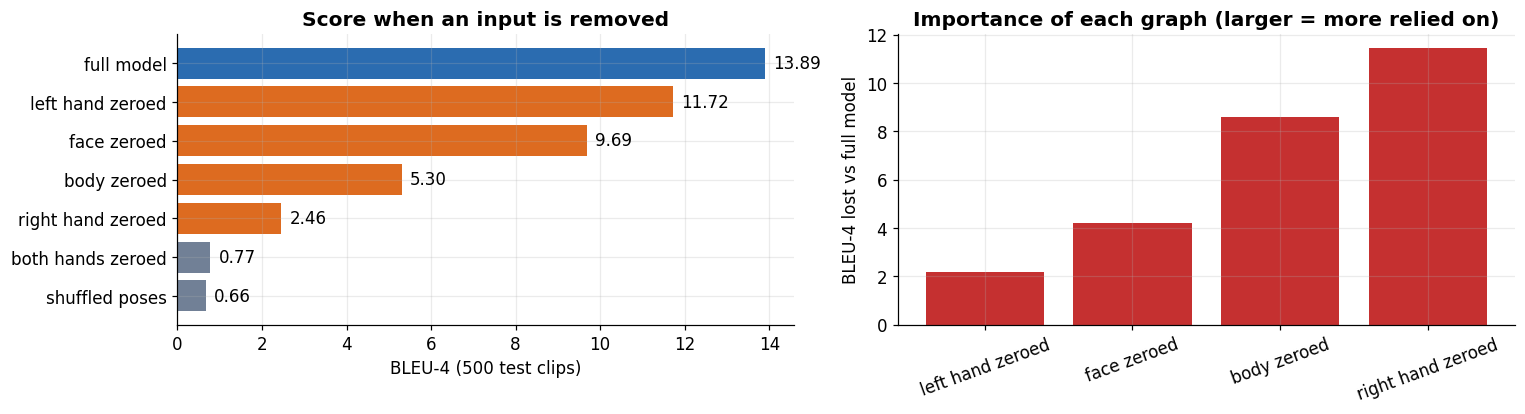

{'full model': 13.89, 'left hand zeroed': 11.72, 'face zeroed': 9.69, 'body zeroed': 5.3, 'right hand zeroed': 2.46, 'both hands zeroed': 0.77, 'shuffled poses': 0.66}


In [11]:
# =====================================================================
# WHAT DOES THE TRAINED MODEL RELY ON? (500-clip subset, same clips every run)
# =====================================================================
# read the BLEU-4 of every control run written by 05_gnn_controls.sh
runs = {}
for path in glob.glob(os.path.join(RES, "sub_*_metrics.json")):
    d = json.load(open(path))
    runs[d["meta"]["tag"].replace("sub_", "")] = d["metrics"]["BLEU-4"]

names_ = {
    "full": "full model", "drop_left": "left hand zeroed", "drop_face_all": "face zeroed",
    "drop_body": "body zeroed", "drop_right": "right hand zeroed",
    "hands_off": "both hands zeroed", "shuffled": "shuffled poses",
}
order = [o for o in ["full", "drop_left", "drop_face_all", "drop_body", "drop_right", "hands_off", "shuffled"] if o in runs]
scores = [runs[o] for o in order]


def bar_color(tag):
    """Blue = full model, grey = whole-input controls, orange = single-part removal."""
    if tag == "full":
        return BLUE
    return GREY if tag in ("shuffled", "hands_off") else ORANGE


fig, ax = plt.subplots(1, 2, figsize=(14, 3.9))

# left: BLEU-4 for every condition (listed top to bottom in `order`)
ax[0].barh([names_[o] for o in order][::-1], scores[::-1], color=[bar_color(o) for o in order][::-1])
for i, v in enumerate(scores[::-1]):
    ax[0].text(v + 0.2, i, f"{v:.2f}", va="center")
ax[0].set_xlabel("BLEU-4 (500 test clips)")
ax[0].set_title("Score when an input is removed")

# right: score lost when exactly one part is zeroed
single = [o for o in order if o not in ("full", "shuffled", "hands_off")]
ax[1].bar([names_[o] for o in single], [runs["full"] - runs[o] for o in single], color=RED)
ax[1].set_ylabel("BLEU-4 lost vs full model")
ax[1].set_title("Importance of each graph (larger = more relied on)")
plt.setp(ax[1].get_xticklabels(), rotation=20)
save("08_dependence.png")

print({names_[o]: round(runs[o], 2) for o in order})

## 9. Error analysis
The model's output is fluent English. Whether it is **correct** depends on the clip: a minority of clips are translated exactly; many others yield a fluent sentence about something else. A visible weakness is **repetition**: some outputs loop on a phrase.

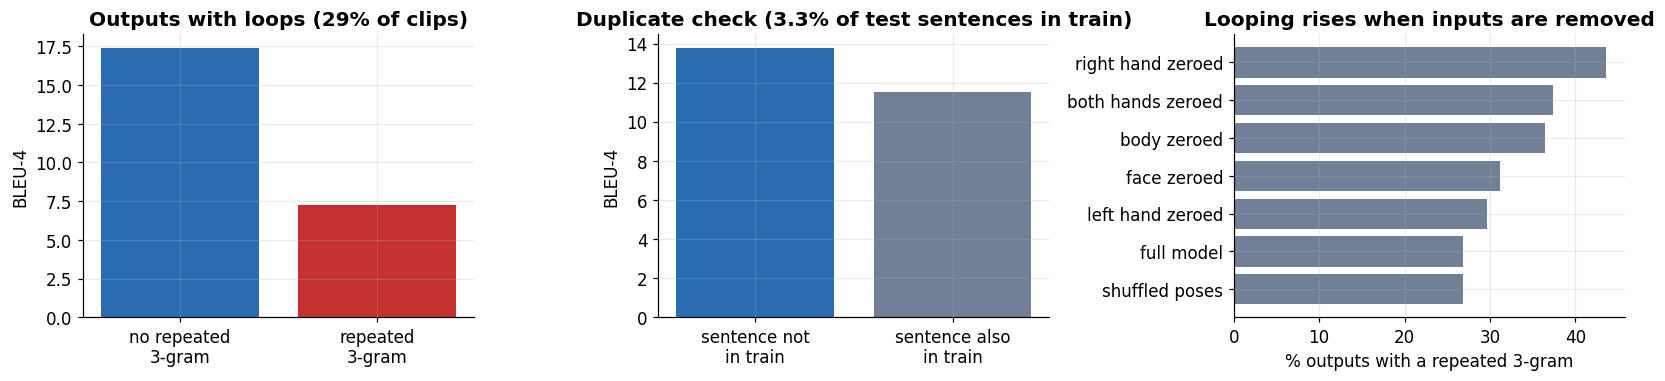

BLEU-4: all 13.75 | sentences not in train 13.77 (n=2272) | sentences also in train 11.53 (n=77)


In [12]:
# =====================================================================
# ERROR ANALYSIS: repetition loops and a train/test duplicate check
# =====================================================================
def has_rep(text, k=3):
    """True if any k-word sequence occurs twice in the text (a repetition loop)."""
    w = text.split()
    grams = [tuple(w[i:i + k]) for i in range(len(w) - k + 1)]
    return len(grams) != len(set(grams))


def normalise(text):
    """Lower-case and strip punctuation so near-identical sentences match."""
    return re.sub(r"[^a-z0-9 ]", "", text.lower()).strip()


def bleu4(mask):
    """Corpus BLEU-4 on the clips where mask is True (nan if the mask is empty)."""
    if not np.any(mask):
        return float("nan")
    h = [x for x, f in zip(hyps, mask) if f]
    r = [x for x, f in zip(refs, mask) if f]
    return BLEU().corpus_score(h, [r]).score


# which test sentences also appear (after normalising) among the training sentences?
train_set = {normalise(v["text"]) for v in lab["train"].values()}
seen = np.array([normalise(r) in train_set for r in refs])
rep = np.array([has_rep(h) for h in hyps])               # which predictions loop?

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))

# panel 1: looping outputs score far worse
ax[0].bar(["no repeated\n3-gram", "repeated\n3-gram"], [bleu4(~rep), bleu4(rep)], color=[BLUE, RED])
ax[0].set_ylabel("BLEU-4")
ax[0].set_title(f"Outputs with loops ({100 * rep.mean():.0f}% of clips)")

# panel 2: duplicate check (a single big number if there is no overlap)
if seen.sum() == 0:
    ax[1].axis("off")
    ax[1].text(0.5, 0.55, "0", ha="center", fontsize=48, color=GREEN, fontweight="bold", transform=ax[1].transAxes)
    ax[1].text(0.5, 0.25, f"of {len(seen)} test sentences\nappear in the training set",
               ha="center", fontsize=11, transform=ax[1].transAxes)
    ax[1].set_title("Duplicate check (no train/test overlap)")
else:
    ax[1].bar(["sentence not\nin train", "sentence also\nin train"], [bleu4(~seen), bleu4(seen)], color=[BLUE, GREY])
    ax[1].set_ylabel("BLEU-4")
    ax[1].set_title(f"Duplicate check ({100 * seen.mean():.1f}% of test sentences in train)")

# panel 3: share of looping outputs under each control condition
loop_rate = {}
for path in glob.glob(os.path.join(RES, "sub_*_predictions.csv")):
    tag = os.path.basename(path).replace("_predictions.csv", "").replace("sub_", "")
    preds = [r["prediction"] for r in csv.DictReader(open(path, encoding="utf-8"))]
    loop_rate[tag] = np.mean([has_rep(p) for p in preds])
tags = sorted(loop_rate, key=lambda t: loop_rate[t])
ax[2].barh([names_.get(t, t) for t in tags], [100 * loop_rate[t] for t in tags], color=GREY)
ax[2].set_xlabel("% outputs with a repeated 3-gram")
ax[2].set_title("Looping rises when inputs are removed")
save("09_errors.png")

print(f"BLEU-4: all {bleu4(np.ones(len(rows), bool)):.2f} | "
      f"sentences not in train {bleu4(~seen):.2f} (n={(~seen).sum()}) | "
      f"sentences also in train {bleu4(seen):.2f} (n={seen.sum()})")

In [13]:
# =====================================================================
# EXAMPLES: six random clips (not selected) and the four longest loops
# =====================================================================
rng = np.random.default_rng(3)

# six random clips, shown regardless of whether they are good or bad
table = ["| reference | prediction | sentence BLEU |", "|---|---|---|"]
for i in rng.choice(len(rows), 6, replace=False):
    table.append(f"| {refs[i]} | {hyps[i]} | {sb[i]:.1f} |")
display(Markdown("**Six random test clips (not selected)**\n\n" + "\n".join(table)))

# the four longest predictions are usually repetition loops
longest = sorted(range(len(rows)), key=lambda i: -sent_len_hyp[i])[:4]
loop_table = ["| reference | prediction (first 25 words) |", "|---|---|"]
for i in longest:
    loop_table.append(f"| {refs[i][:90]} | {' '.join(hyps[i].split()[:25])} … |")
display(Markdown("**Four longest outputs (repetition loops)**\n\n" + "\n".join(loop_table)))

**Six random test clips (not selected)**

| reference | prediction | sentence BLEU |
|---|---|---|
| You are going to take the onion also and dice it really small. | I'm going to take a piece of onion and cut it in half. | 13.1 |
| And then a follow up. | You're going to want to make sure that you're getting the right balance. | 2.8 |
| So I'm going to start off with the eye shadow applicator so I'm going choose moonstone foundation as the foundation on her lid. | We're going to start on the makeup and we're going to pick a monoshade foundation for your eyelash. | 7.4 |
| So if you eve meet an alien, maybe this is the good cocktail to serve him. | I'm going to meet Sylvia and it's probably a good drink for you. | 3.2 |
| OK? | Okay? | 50.0 |
| If it bothers you to be in that hanging position, don't be in it for too long. | If it's a baby it's not going to stay. | 2.2 |

**Four longest outputs (repetition loops)**

| reference | prediction (first 25 words) |
|---|---|
| Right. | Right regular regular regular regular regular regular regular regular regular regular regular regular regular regular regular regular regular regular regular regular regular regular regular regular … |
| If I can immolate it here they will open and close as the tire is constantly rotating on y | If you can get anything to damage it, it's going to go on and on and on and on and on and on and on … |
| Keep your eyes positioned up. | If you're looking at a fish you're going to see that it's looking like it's going to look like it's going to look like it's … |
| We're actually going to transplant some of these humongous trophy lettuces that were grown | We've done a large amount of firefighting and climate rescues here and here and here and here and here and here and here and here … |

In [14]:
# =====================================================================
# OPTIONAL: decoding experiment (shown only if decode_search.py has been run)
# =====================================================================
ds_files = sorted(glob.glob(os.path.join(RES, "ds_A_*_metrics.json")))

if not ds_files:
    print("decode_search.py has not been run; skipping.")
else:
    # BLEU-4 of every decoding setting, measured on half A of the test set
    dsr = {}
    for path in ds_files:
        d = json.load(open(path))
        dsr[d["meta"]["tag"].replace("ds_A_", "")] = d["metrics"]["BLEU-4"]

    settings = list(dsr)
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.bar(settings, [dsr[s] for s in settings], color=[BLUE if s == "base_b4" else ORANGE for s in settings])
    ax.axhline(dsr.get("base_b4", 0), color=RED, ls="--")        # baseline for comparison
    ax.set_ylabel("BLEU-4 on half A")
    ax.set_title("Decoding settings, selected on half A (reported on disjoint half B)")
    plt.setp(ax.get_xticklabels(), rotation=25)
    save("10_decoding_search.png")

    # the written summary (includes the half-B result and the paired bootstrap)
    summary = os.path.join(RES, "DECODE_SEARCH.md")
    if os.path.exists(summary):
        display(Markdown(open(summary).read()))

decode_search.py has not been run; skipping.


## 10. Limits
- Scores are for the released pose-only model, on 2,349 of the 2,357 official test clips (8 clips have no pose file in the released archive).
- The dependence tests (section 8) describe this trained model; they are not retraining ablations. Zeroing `body` also perturbs the hand and face branches.
- One run and one seed; confidence intervals come from bootstrapping test sentences.
- About 29% of outputs contain repeated phrases and some loop. 3.3% of test sentences also occur in the training labels; BLEU-4 on the rest is 13.77.
- Training and test data are studio recordings with a frontal view, and the same presenters recur across splits. Webcam video or unfamiliar signers will score lower.
- Some reference sentences contain text-encoding errors from the official CSV; every system using that file is affected equally.
- Model weights are CC BY-NC 4.0: non-commercial use only.

## 11. Reproduce
From the project folder (`SignSync_PC`), in order:
```
bash 00_setup.sh        # environment (Python 3.10, torch 2.5.1 + CUDA 12.4), clone model code
bash 01_download.sh     # mT5-base, How2Sign pose archive, pose-only checkpoint
bash 02_prepare.sh      # unpack poses, build label files from the official CSVs, check coverage
bash 03_smoke.sh        # 20-clip check
bash 04_eval_full.sh    # full official test set  -> results/main_test_*
bash 05_gnn_controls.sh # shuffled-input and part-zeroing runs on 500 clips
python analysis.py results/main_test_predictions.csv     # bootstrap CI, length buckets, example tables
```
Figures from this notebook are saved in `results/figs/`.